# Using Transfer Learning Models for FER2013 Classification - Part 2
## Imports:

The only chnage made in this import cell is the addition of:
```python
loss_fn = tf.keras.losses.CategoricalFocalCrossentropy()
```
This is used later when creating the model dictionary for the top three models from Transfer_part1.

In [1]:
import os

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.utils.class_weight import compute_class_weight
import gc

from src.config import EMOTION_LABELS, EMOTION_LOOKUP
from src.training import evaluate_model
from src.model_config import TL_MODELS

tf.get_logger().setLevel("ERROR")

options = tf.data.Options()

options.experimental_optimization.map_parallelization = True
options.experimental_optimization.parallel_batch = True

tf.config.threading.set_inter_op_parallelism_threads(0)
tf.config.threading.set_intra_op_parallelism_threads(0)

gpus = tf.config.list_physical_devices("GPU")

if gpus:
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)

tf.keras.mixed_precision.set_global_policy('mixed_float16')

loss_fn = tf.keras.losses.CategoricalFocalCrossentropy()

I0000 00:00:1784882036.995521  255604 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:06:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1784882037.093988  255604 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:06:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1784882037.094043  255604 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:06:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1784882037.095383  255604 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:06:00.0/numa_node
Your kernel may have been built without NUMA support.


## Data:

In [2]:
df = pd.read_csv("data/fer2013.csv")

train_df = df[df["Usage"] == "Training"]
train_df["label"] = train_df["emotion"].map(EMOTION_LOOKUP)
val_df = df[df["Usage"] == "PublicTest"]
val_df["label"] = val_df["emotion"].map(EMOTION_LOOKUP)
test_df = df[df["Usage"] == "PrivateTest"]
test_df["label"] = test_df["emotion"].map(EMOTION_LOOKUP)

train_df.to_csv("data/training_data.csv", index=False)
val_df.to_csv("data/validation_data.csv", index=False)
test_df.to_csv("data/testing_data.csv", index=False)

/tmp/ipykernel_255604/1510110141.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_df["label"] = train_df["emotion"].map(EMOTION_LOOKUP)
/tmp/ipykernel_255604/1510110141.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  val_df["label"] = val_df["emotion"].map(EMOTION_LOOKUP)
/tmp/ipykernel_255604/1510110141.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: 

## Calculate Class Weights:

One of the most persistent issues throughout the project was class imbalance. The training set contains substantially different numbers of samples for each emotion category, meaning that standard training tends to favour majority classes.

This became particularly apparent during Transfer Part 1 when some models achieved acceptable validation accuracy but still struggled to identify less common emotions correctly.

The weighting strategy attempts to compensate for imbalance by increasing the training penalty associated with mistakes on rare classes. During optimisation, misclassifying a rare emotion therefore contributes more heavily to the loss function than misclassifying a common emotion. This encourages the model to pay greater attention to minority classes.

In [3]:
classes = np.unique(train_df["emotion"].values)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["emotion"].values
)

class_weights = dict(zip(classes, class_weights))
class_weights

{0: 1.0266046844269623,
 1: 9.406618610747051,
 2: 1.0010460615781582,
 3: 0.5684387684387684,
 4: 0.8491274770777877,
 5: 1.293372978330405,
 6: 0.8260394187886635}

## Selecting Transfer_part1's Best Three:

Rather than manually selecting models for further experimentation, this code automatically extracts the top three performers:
```python
top_models = TL_comparison_df["Model"].head(3).tolist()
```
Meaning that Transfer_part2 is driven directly by the results of Part 1, creating a reproducible model-selection process.

In [4]:
TL_comparison_df = pd.read_csv("results/TL_model_comparison_part1.csv")

top_models = TL_comparison_df["Model"].head(3).tolist()

TL_models = TL_MODELS

## Create The Dictionary Of Models For Part 2:

Using `**base_config` copies the entire original configuration automatically before modifying only the required fields.

This ensures Architecture, Batch Size, Dense Layers, and Unfrozen Layers remain identical to the successful Part 1 configuration.

In [5]:
second_stage_TL_models = {}

for model_name in top_models:

    base_config = TL_models[model_name]

    second_stage_TL_models[f"{model_name}_Weighted"] = {
        **base_config,
        "loss": "categorical_crossentropy",
        "class_weight": class_weights
    }

    second_stage_TL_models[f"{model_name}_Focal"] = {
        **base_config,
        "loss": loss_fn,
        "class_weight": None
    }

    second_stage_TL_models[f"{model_name}_Weighted_Focal"] = {
        **base_config,
        "loss": loss_fn,
        "class_weight": class_weights
    }

## Run All Models `num_runs` Times:

In [6]:
for model_name, config in second_stage_TL_models.items():
    try:
        result = evaluate_model(
            model_fn=config["model_fn"],
            model_name=model_name,
            loss=config["loss"],
            class_weight=config["class_weight"],
            model_kwargs=config["model_kwargs"],
            train_df=train_df,
            val_df=val_df,
            test_df=test_df,
            batch_size=config["batch_size"],
            emotion_labels=EMOTION_LABELS,
            num_runs=5
        )
    except Exception as e:
        print(f"{model_name} failed:")
        print(e)
        
        gc.collect()
        continue

    if result is None:
        print(f"{model_name} skipped")
        continue

    del result

    gc.collect()


Training VGG16_Unfreeze4_Weighted


I0000 00:00:1784882047.585728  255604 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:06:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1784882047.585797  255604 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:06:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1784882047.585823  255604 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:06:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1784882047.773317  255604 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:06:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1784882047.773396  255604 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:06:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:0

VGG16_Unfreeze4_Weighted: Run 1/5 (batch=256)
RAM: 1.63 GB


'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)
'+ptx85' is not a recognized feature for this target (ignoring feature)


W0000 00:00:1784882050.436957  255688 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1784882050.447457  255688 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1784882050.448469  255688 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1784882050.449445  255688 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1784882050.456074  255688 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1784882050.457073  255688 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1784882050.466173  255688 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1784882050.534991  255688 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1784882050.537316  255688 gp

W0000 00:00:1784882050.637546  255688 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1784882050.640156  255688 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1784882050.642798  255688 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1784882050.644813  255688 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1784882050.646244  255688 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1784882050.648790  255688 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1784882050.650700  255688 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1784882050.653452  255688 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1784882050.656114  255688 gp

... (191 outputs left out)

InceptionV3_Unfreeze4_Head_Weighted_Focal Run 4 failed at minimum batch size


InceptionV3_Unfreeze4_Head_Weighted_Focal: Run 5/5 (batch=4)
RAM: 5.20 GB


InceptionV3_Unfreeze4_Head_Weighted_Focal Run 5 OOM at batch size 4


InceptionV3_Unfreeze4_Head_Weighted_Focal Run 5 failed at minimum batch size
InceptionV3_Unfreeze4_Head_Weighted_Focal complete (best run = 2, best val acc = 0.4519)


## Combine Dictionaries For Visualisation And Evaluation:

By merging both dictionaries into `all_TL_models`, the remainder of the analysis can treat every model as part of a single experiment set. An important consideration was ensuring that Part 2 did not overwrite Part 1.

In [7]:
all_TL_models = {
    **TL_models,
    **second_stage_TL_models
}

## Visualisation:

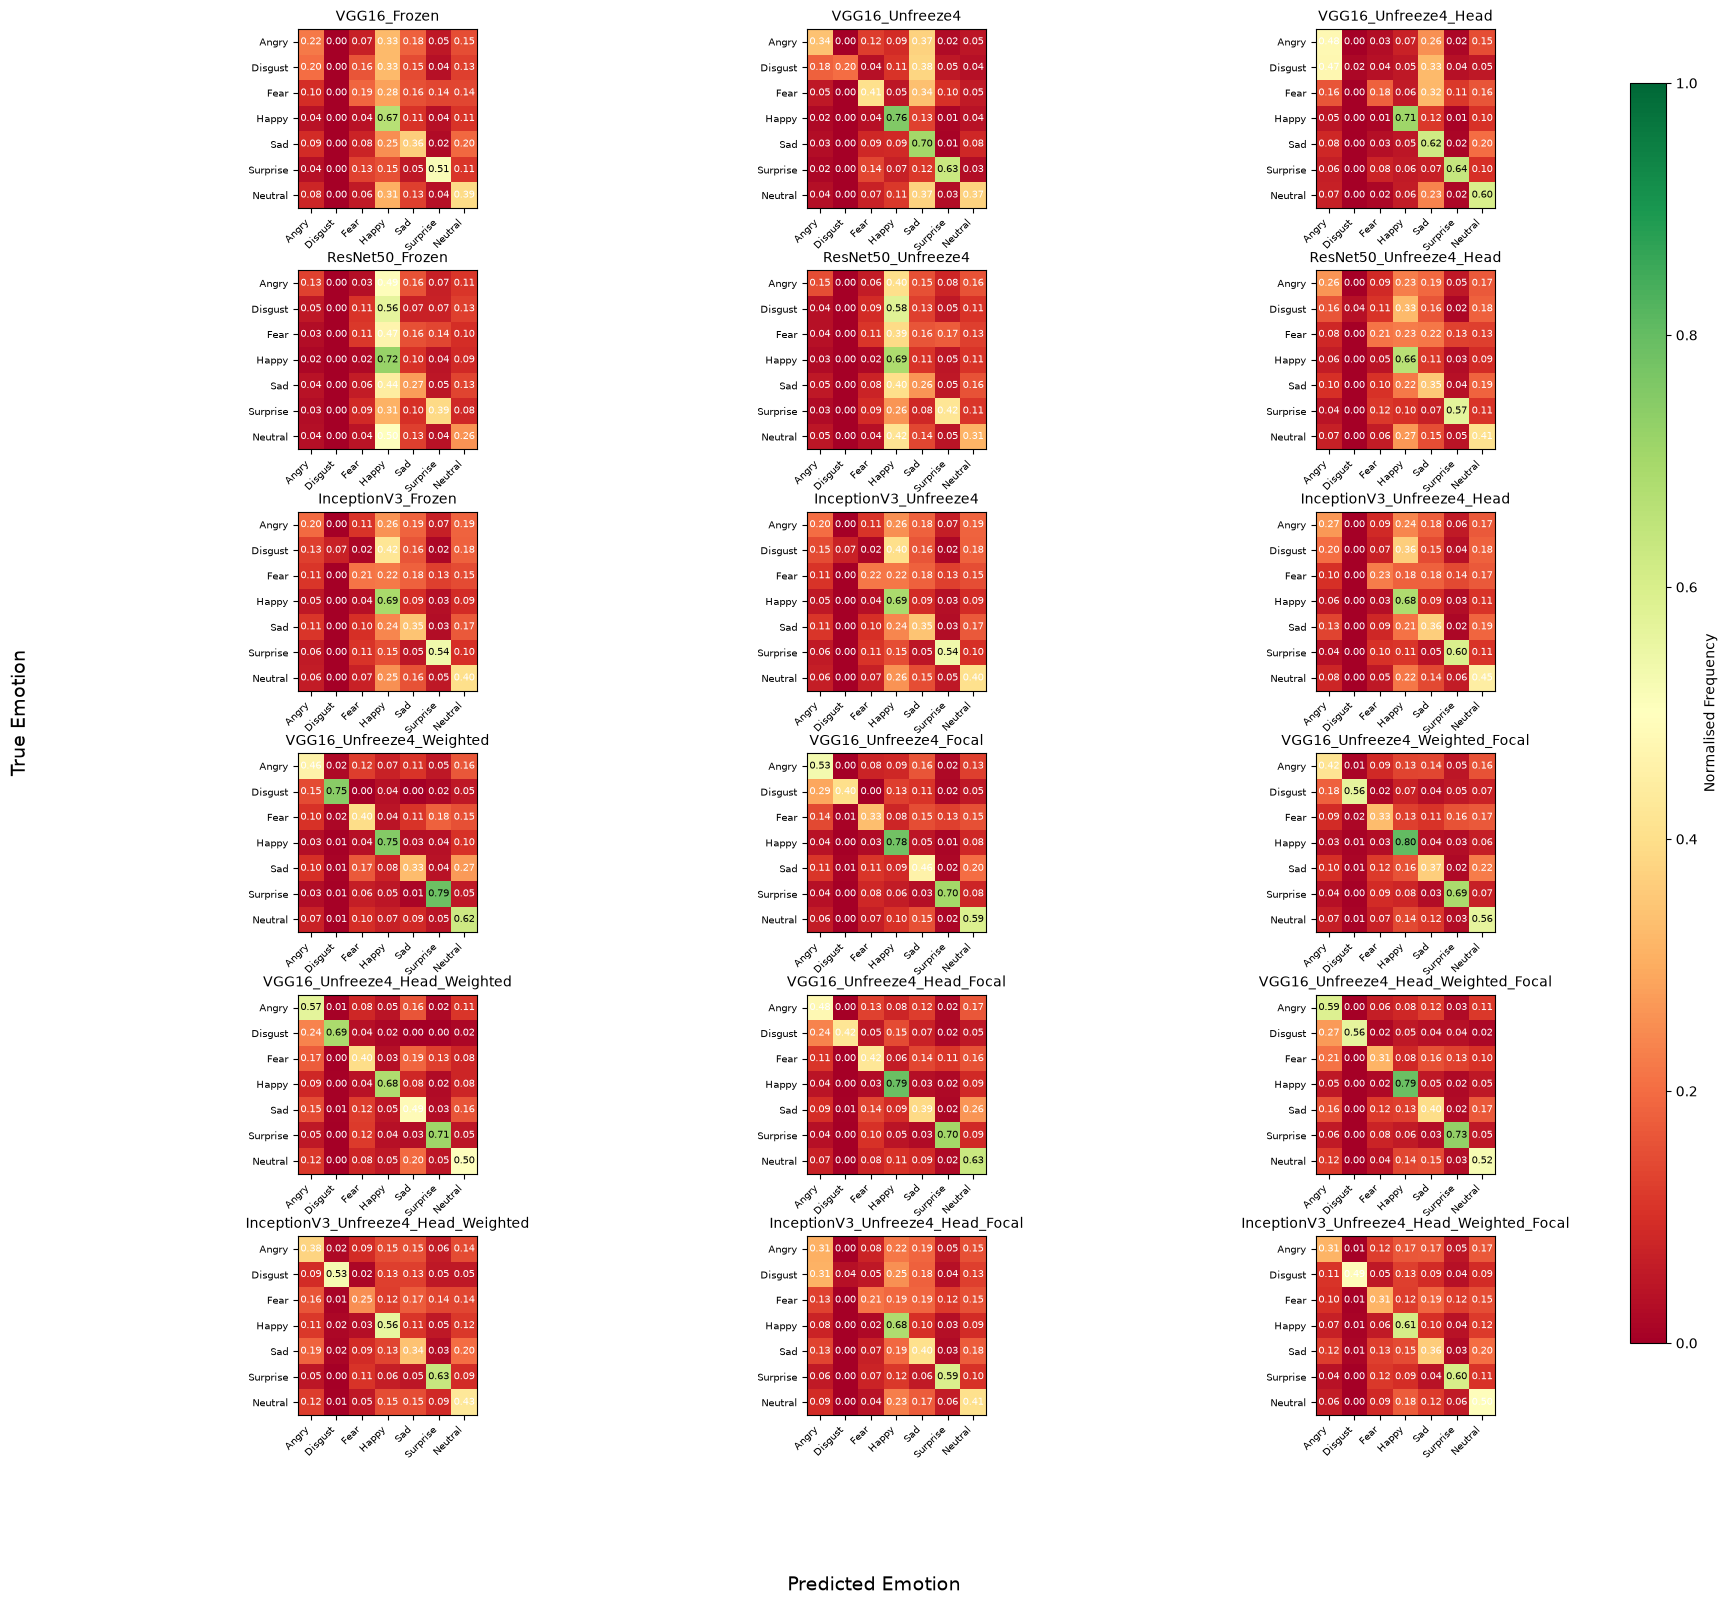

In [8]:
fig, axes = plt.subplots(6, 3, figsize=(18, 18))

axes = axes.flatten()

model_names = list(all_TL_models.keys())

vmin = 0
vmax = 1

for ax, model_name in zip(axes, model_names):

    cm = pd.read_csv(
        f"confusion_matrices/{model_name}.csv"
    ).values

    im = ax.imshow(
        cm,
        cmap="RdYlGn",
        vmin=vmin,
        vmax=vmax
    )

    ax.set_title(model_name, fontsize=10)

    ax.set_xticks(np.arange(len(EMOTION_LABELS)))

    ax.set_yticks(np.arange(len(EMOTION_LABELS)))

    ax.set_xticklabels(
        EMOTION_LABELS,
        rotation=45,
        ha="right",
        fontsize=7
    )

    ax.set_yticklabels(
        EMOTION_LABELS,
        fontsize=7
    )

    threshold = 0.50

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            value = cm[i, j]

            ax.text(
                j, i, f"{value:.2f}",
                ha="center", va="center",
                color=(
                    "white"
                    if value < threshold
                    else "black"
                ),
                fontsize=7
            )

for ax in axes[len(model_names):]:
    ax.axis("off")

fig.supxlabel("Predicted Emotion", fontsize=14)

fig.supylabel("True Emotion", fontsize=14)

fig.subplots_adjust(
    right=0.90,
    wspace=0.35,
    hspace=0.35
)

cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])

fig.colorbar(
    im,
    cax=cbar_ax,
    label="Normalised Frequency"
)

plt.show()

## Evaluation:

Rather than identifying merely the most accurate transfer learning model, the code attempts to identify the strongest overall model when accuracy, robustness, fairness across classes, and computational cost are all considered simultaneously.

Consequently - since it itterates over `all_TL_models`, `TL_model_comparison_part2.csv` becomes the final transfer learning leaderboard used to determine the best-performing transfer learning solution in the project.

In [9]:
comparison_rows = []

for model_name in all_TL_models.keys():

    summary = pd.read_csv(
        f"results/{model_name}_summary.csv",
        index_col=0
    )

    report = pd.read_csv(
        f"reports/{model_name}_classification_report.csv",
        index_col=0
    )

    comparison_rows.append({
        "Model": model_name,
        "Mean Validation Accuracy":summary.loc["val_accuracy", "Mean"],
        "Mean Test Accuracy":summary.loc["test_accuracy", "Mean"],
        "Mean Balanced Accuracy":summary.loc["balanced_accuracy", "Mean"],
        "Mean Epochs":summary.loc["epochs", "Mean"],
        "Mean Training Time (s)":summary.loc["training_time_seconds", "Mean"],
        "Macro Precision":report.loc["macro avg", "precision"],
        "Macro Recall":report.loc["macro avg", "recall"],
        "Macro F1":report.loc["macro avg", "f1-score"],
        "Weighted F1":report.loc["weighted avg", "f1-score"],
        "Validation Accuracy Std": summary.loc["val_accuracy", "Std Dev"]
    })

TL_comparison_df = pd.DataFrame(comparison_rows)

TL_comparison_df["Efficiency Score"] = (
    TL_comparison_df["Mean Balanced Accuracy"] /
    TL_comparison_df["Mean Training Time (s)"]
)

TL_comparison_df = TL_comparison_df.sort_values(
    by=[
        "Mean Balanced Accuracy",
        "Macro F1",
        "Mean Validation Accuracy",
        "Mean Training Time (s)",
        "Validation Accuracy Std"
    ],
    ascending=[False, False, False, True, True]
)

TL_comparison_df.to_csv("results/TL_model_comparison_part2.csv", index=False)

TL_comparison_df

,Model,Mean Validation Accuracy,Mean Test Accuracy,Mean Balanced Accuracy,Mean Epochs,Mean Training Time (s),Macro Precision,Macro Recall,Macro F1,Weighted F1,Validation Accuracy Std,Efficiency Score
14,VGG16_Unfreeze4_Head_Weighted_Focal,0.563500,0.570242,0.564552,25.4,70.224883,0.595135,0.557761,0.567458,0.563021,0.012031,0.008039
12,VGG16_Unfreeze4_Head_Weighted,0.583728,0.556812,0.558163,16.4,49.225743,0.581770,0.576242,0.575920,0.568679,0.006127,0.011339
9,VGG16_Unfreeze4_Weighted,0.585233,0.559599,0.554013,15.6,45.950785,0.548847,0.584578,0.557947,0.564980,0.004256,0.012057
10,VGG16_Unfreeze4_Focal,0.569629,0.577542,0.533399,22.6,60.015095,0.565468,0.541976,0.549571,0.574660,0.007413,0.008888
11,VGG16_Unfreeze4_Weighted_Focal,0.525495,0.532627,0.520541,18.8,51.547866,0.519772,0.532618,0.521214,0.537765,0.010194,0.010098
13,VGG16_Unfreeze4_Head_Focal,0.572360,0.561884,0.501026,18.2,51.179722,0.598750,0.546805,0.562656,0.579463,0.013931,0.009790
1,VGG16_Unfreeze4,0.583728,0.555252,0.490085,14.4,39.171017,0.611140,0.486915,0.505358,0.547557,0.007193,0.012511
2,VGG16_Unfreeze4_Head,0.584620,0.549067,0.463059,15.0,42.773733,0.527316,0.462827,0.457913,0.537553,0.005203,0.010826
17,InceptionV3_Unfreeze4_Head_Weighted_Focal,0.450404,0.455141,0.452089,42.0,308.515583,0.461712,0.454772,0.456706,0.457385,0.002167,0.001465
15,InceptionV3_Unfreeze4_Head_Weighted,0.450098,0.442909,0.451411,23.0,181.225284,0.423945,0.445757,0.430182,0.435670,0.007001,0.002491
